In [6]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.autograd import Variable
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torch.utils.data import Subset
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [10]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 64 x 16 x 16

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 128 x 8 x 8

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # output: 256 x 4 x 4

            nn.Flatten(), 
            nn.Linear(256*4*4, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10))
        
    def forward(self, xb):
        return self.network(xb)

In [3]:

class VAE(nn.Module):
    def __init__(self, latent_dim=100):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(256*4*4, self.latent_dim * 2)
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(self.latent_dim, 256*4*4),
            nn.ReLU(),
            nn.Unflatten(1, (256, 4, 4)),
            nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        encoded = self.encoder(x)
        mu, log_var = torch.chunk(encoded, 2, dim=1)
        z = self.reparameterize(mu, log_var)
        return self.decoder(z), mu, log_var
    
def vae_loss(true, sq, mu, log_var):
    recon_loss = nn.functional.mse_loss(sq, true, reduction='sum') / sq.numel()
    kl_div = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / mu.numel()
    return recon_loss + kl_div, recon_loss, kl_div

In [3]:
def train(model, data_loader, optimizer):
    model.train()
    total_loss, recon_loss, kl_loss = 0, 0, 0
    for idx, (images, _) in enumerate(data_loader):
        images = images.to(device)
        optimizer.zero_grad()
        reconstructed, mu, log_var = model(images)
        loss, r_loss, k_loss = vae_loss(images, reconstructed, mu, log_var)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        recon_loss += r_loss.item()
        kl_loss += k_loss.item()
    return total_loss / len(data_loader), recon_loss / len(data_loader), kl_loss / len(data_loader)

Files already downloaded and verified


 10%|█         | 1/10 [00:13<02:02, 13.64s/it]

Epoch [1/10], Total Loss: 0.0591, Reconstruction Loss: 0.0545, KL Div: 0.0046


 20%|██        | 2/10 [00:27<01:49, 13.74s/it]

Epoch [2/10], Total Loss: 0.0581, Reconstruction Loss: 0.0525, KL Div: 0.0056


...

Epoch [7/10], Total Loss: 0.0554, Reconstruction Loss: 0.0481, KL Div: 0.0073


 80%|████████  | 8/10 [01:49<00:27, 13.56s/it]

Epoch [8/10], Total Loss: 0.0554, Reconstruction Loss: 0.0481, KL Div: 0.0073


 90%|█████████ | 9/10 [02:03<00:13, 13.58s/it]

Epoch [9/10], Total Loss: 0.0554, Reconstruction Loss: 0.0481, KL Div: 0.0073
Epoch [10/10], Total Loss: 0.0553, Reconstruction Loss: 0.0480, KL Div: 0.0073


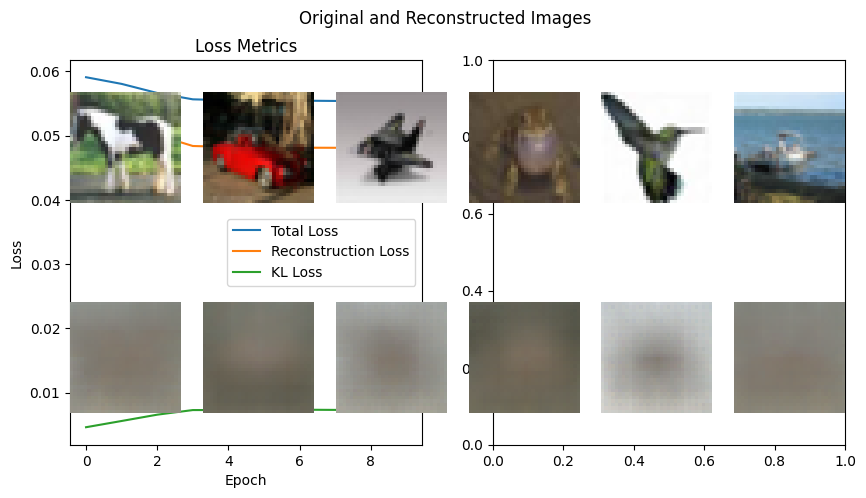

100%|██████████| 10/10 [02:17<00:00, 13.71s/it]


In [ ]:
#traing the model
model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Lists to store loss metrics
epoch_losses, epoch_recon_losses, epoch_kl_losses = [], [], []

# Train the model
epochs = 10
for epoch in tqdm(range(epochs)):
    loss, recon_loss, kl_loss = train(model, train_loader, optimizer)
    epoch_losses.append(loss)
    epoch_recon_losses.append(recon_loss)
    epoch_kl_losses.append(kl_loss)    
    if (epoch + 1) % 10 == 0:
        # Plot losses
        print(f'Epoch [{epoch+1}/{epochs}], Total Loss: {loss:.4f}, Reconstruction Loss: {recon_loss:.4f}, KL Div: {kl_loss:.4f}')
        plt.figure(figsize=(10, 5))
        plt.subplot(1, 2, 1)
        plt.plot(epoch_losses, label='Total Loss')
        plt.plot(epoch_recon_losses, label='Reconstruction Loss')
        plt.plot(epoch_kl_losses, label='KL Loss')
        plt.title('Loss Metrics')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
        plt.show()

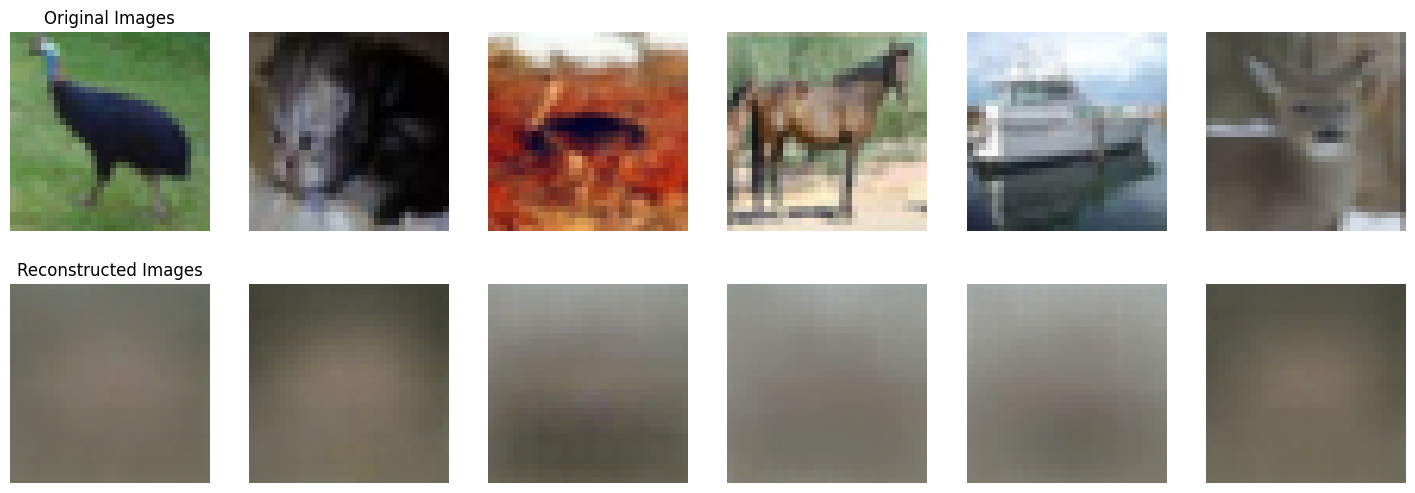

In [6]:
import matplotlib.pyplot as plt

def visualize_reconstructions(model, data_loader, num_images=6):
    model.eval() 
    images, _ = next(iter(data_loader)) 
    images = images.to(device)[:num_images] 
    with torch.no_grad():
        reconstructions, _, _ = model(images)
    
    images = images.cpu().numpy().transpose(0, 2, 3, 1)
    reconstructions = reconstructions.cpu().numpy().transpose(0, 2, 3, 1)
    
    fig, axs = plt.subplots(2, num_images, figsize=(num_images * 3, 6))
    for i in range(num_images):
        axs[0, i].imshow(images[i], interpolation='none')
        axs[0, i].axis('off')
        axs[1, i].imshow(reconstructions[i], interpolation='none')
        axs[1, i].axis('off')
    
    axs[0, 0].set_title('Original Images')
    axs[1, 0].set_title('Reconstructed Images')
    plt.show()

visualize_reconstructions(model, train_loader)

In [ ]:
#save the model
torch.save(model.state_dict(), 'vae_cifar10.pth')

In [28]:
#load model from .pth
model = VAE().to(device)
model.load_state_dict(torch.load('vae_cifar10_100.pth'))


C:\Users\M LAKSHMI NARASIMHA\AppData\Local\Temp\ipykernel_26080\691780660.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('vae_cifar10_1

<All keys matched successfully>

In [29]:
transform = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((.5, .5, .5), (.5, .5, .5))
        ])
dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

data, targets = dataset.data, dataset.targets
label_datasets = {}

for label in range(10):
    indices = [i for i, t in enumerate(targets) if t == label]
    label_datasets[label] = Subset(dataset, indices)

Files already downloaded and verified


In [30]:
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
train_dataset1 = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
train_dataset1.data = train_dataset.data[:4096]
train_dataset1.targets = train_dataset.targets[:4096]

Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


In [31]:
new_dataset = train_dataset1
for i in range(10):
    label_datasets[i] = DataLoader(label_datasets[i], batch_size=8, shuffle=True)
    images_new = []
    targets_new = []
    for images, _ in label_datasets[i]:
        images = images.to(device)
        with torch.no_grad():
            reconstructions, _, _ = model(images)
        images_new.extend(reconstructions)
        targets_new.extend(_)
    images_new = torch.stack(images_new[:400])
    targets_new = torch.stack(targets_new[:400])
    vae_dataset = torch.utils.data.TensorDataset(images_new, targets_new)
    new_dataset = torch.utils.data.ConcatDataset([new_dataset, vae_dataset])
    

In [32]:
len(new_dataset)

8096

In [33]:
def train_cnn(cnn_model, loader, criterion, optimizer):
    cnn_model.train()
    total_loss, total_correct = 0, 0
    for epoch in range(100):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = cnn_model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader), total_correct / len(loader.dataset)

def validate_cnn(cnn_model, loader):
    cnn_model.eval()
    total_correct = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = cnn_model(images)
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_correct / len(loader.dataset)

In [34]:
train_cnn_model = CNN().to(device)
train_cnn_criterion = nn.CrossEntropyLoss()
train_cnn_optimizer = optim.Adam(train_cnn_model.parameters(), lr=0.001)

loader = DataLoader(train_dataset1, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
train_cnn(train_cnn_model, loader, train_cnn_criterion, train_cnn_optimizer)
accuracy = validate_cnn(train_cnn_model, test_loader)
accuracy

0.4667

In [35]:
train_cnn_model = CNN().to(device)
train_cnn_criterion = nn.CrossEntropyLoss()
train_cnn_optimizer = optim.Adam(train_cnn_model.parameters(), lr=0.001)
loader = DataLoader(new_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
train_cnn(train_cnn_model, loader, train_cnn_criterion, train_cnn_optimizer)
accuracy = validate_cnn(train_cnn_model, test_loader)
accuracy

RuntimeError: Expected all tensors to be on the same device, but found at least two devices, cuda:0 and cpu! (when checking argument for argument tensors in method wrapper_CUDA_cat)